# 4. The rain forecast: when the right answer is "don't deploy"

The concept note wants to flag season shortfalls ahead of time. So we try it, as carefully as we can, and let the evidence decide.

**Question:** after the first month of a season, will the rest of it fall in the driest fifth of that commune's history?

In [1]:
import json, os, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ["IMBUTO_ROOT"] = str(ROOT)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
GREEN, GREY, BROWN = "#1f6e3f", "#9aa89f", "#8c510a"

In [2]:
import warnings; warnings.filterwarnings("ignore")
from imbuto.ml import risk
gold = pd.read_parquet(ROOT / "data/gold/season_features.parquet")
print(gold.groupby("season").year.agg(["min", "max"])); print("Features:", risk.FEATURES)

         min   max
season            
A       1981  2026
B       1982  2026
Features: ['z_so_far', 'z_prior', 'z_last', 'oni', 'dmi', 'is_season_a']


## Three traps in this problem

1. **Random splits leak the future.** A random split trains on 2020 and tests on 2015. We walk forward: to test a year, train only on years before it.
2. **Rows are not independent.** All 119 communes share one sky, so a season is really one observation. We have about 40 test seasons, not 4,800 test rows. Our confidence interval resamples whole seasons.
3. **Anomalies can leak too.** "Dry compared to normal" must use only the past's normal.

## The baseline

A model must beat something. Our yardstick is climatology: always predict the base rate. **Brier skill** is how much better than that yardstick the model is. Zero means it adds nothing.

In [3]:
results = risk.backtest(gold)
models = ["logistic", "gradient_boosting"]
report = risk.evaluate(results, models)
table = pd.DataFrame(report).T[["brier_skill", "brier_skill_ci90", "auc"]]
print(f"{len(results):,} test rows over {results.groupby(['year', 'season']).ngroups} seasons"); table

4,879 test rows over 41 seasons


,brier_skill,brier_skill_ci90,auc
logistic,0.002,"[-0.077, 0.084]",0.593
gradient_boosting,-0.059,"[-0.206, 0.072]",0.58


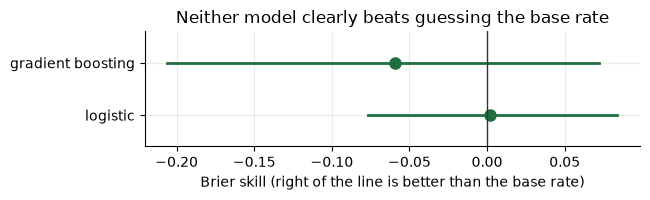

In [4]:
fig, ax = plt.subplots(figsize=(6.6, 2.1))
for i, name in enumerate(models):
    r = report[name]; low, high = r["brier_skill_ci90"]
    ax.plot([low, high], [i, i], color=GREEN, lw=2); ax.plot(r["brier_skill"], i, "o", color=GREEN, ms=8)
ax.axvline(0, color="#333", lw=1); ax.set_yticks(range(2), ["logistic", "gradient boosting"]); ax.set_ylim(-.6, 1.6)
ax.set(xlabel="Brier skill (right of the line is better than the base rate)", title="Neither model clearly beats guessing the base rate"); plt.tight_layout(); plt.show()

**This is the most important result in the series.** The code works. The data is real. Accuracy, if we had quoted it, would look great: about 85% of the time, a season is simply not a shortfall. And yet the model tells us nothing reliable.

A few things worth noticing:

- The simple logistic regression beat gradient boosting. More complex is not automatically better, especially with few independent seasons.
- We also tried whole-season totals and excess rain, with climate and rain feature subsets. None gave an interval clear of zero. **Then we stopped.** Keep trying and something will eventually look good by chance. That is called the garden of forking paths.

## The gate

We wrote the rule *before* looking at the final numbers, and made it code, so nobody can argue with it at 2 a.m. before a launch.

In [5]:
gate = risk.promotion_gate(report); gate

{'best_model': 'logistic',
 'rule': 'lower bound of 90% interval on Brier skill must exceed 0',
 'lower_bound': -0.077,
 'passed': False}

## What ships instead

Farmers get measured rainfall against their commune's own record. That is less exciting than a forecast, but it is true. The forecast stays on the analyst dashboard, labelled experimental.

This is also useful: a late start to the rains is exactly the signal that shapes planting decisions.

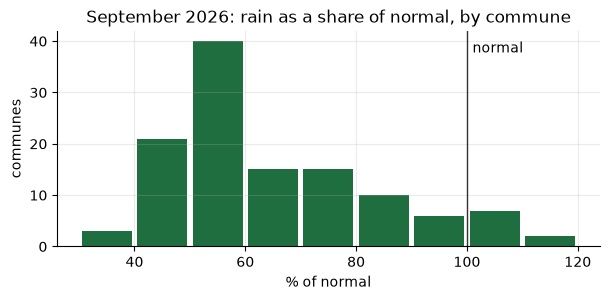

Median commune: 59% of normal, one month into Season A


In [6]:
status = json.loads((ROOT / "artifacts/rain/rain_status.json").read_text())
rows = pd.DataFrame(status["communes"])
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(rows.percent_of_normal, bins=range(30, 121, 10), color=GREEN, rwidth=.9)
ax.axvline(100, color="#333", lw=1); ax.annotate("normal", (101, ax.get_ylim()[1] * .9))
ax.set(title=f"September {status['year']}: rain as a share of normal, by commune", xlabel="% of normal", ylabel="communes"); plt.show()
print(f"Median commune: {rows.percent_of_normal.median():.0f}% of normal, one month into Season A")

## A signal to watch, not a forecast

NOAA's ONI is strongly positive this year, a strong El Nino signal. The table shows the highest past values at the same point in the season, with the rest of Season A that followed. This year's value is higher than any of them, so there is no true precedent here. **This is a handful of years, and one was slightly below average.** It is context for discussion with IGEBU and ICPAC, not something to tell a farmer.

In [7]:
season_a = gold[gold.season == "A"].dropna(subset=["target_rain"]).groupby("year").agg(rest_of_season_mm=("target_rain", "mean"), oni=("oni", "first"))
season_a["vs_average_%"] = (season_a.rest_of_season_mm / season_a.rest_of_season_mm.mean() * 100).round()
print("Latest ONI in the data:", status["oni_latest"])
season_a.sort_values("oni").tail(5).round(2)

Latest ONI in the data: 2.16


,rest_of_season_mm,oni,vs_average_%
year,,,
1982,622.76,0.78,104.0
2023,661.75,1.00,111.0
1987,585.27,1.30,98.0
2015,761.12,1.44,128.0
1997,774.57,1.48,130.0


## What would change the result

- Dynamical seasonal forecasts from ICPAC or IGEBU, which carry real ocean-atmosphere physics
- Soil moisture and NDVI, which are closer to crop outcomes
- Yield or IPC labels, so the target is about food, not only rain

Each is a reason to partner. Each can go through this exact gate.

**Next:** notebook 5 packages the models that passed.